The second tally-focused example

In [1]:
import openmc
import numpy as np

# Material definitions
materials=openmc.Materials()

m999 = openmc.Material()
m999.add_nuclide('O16', 8)
m999.add_nuclide('H1', 1)
m999.set_density('g/cc',1.0)
materials.append(m999)

m1001 = openmc.Material()
m1001.add_nuclide('Li6', 0.0742)
m1001.add_nuclide('Li7', 0.9258)
m1001.set_density('g/cc',1.0)
materials.append(m1001)

In [2]:
# Surface definition
s1 = openmc.Sphere(r=5)
s2 = openmc.Sphere(r=6,boundary_type='vacuum')

# Cell definition
c10 = openmc.Cell(fill=m999,region=-s1) 
c11 = openmc.Cell(fill=m1001,region=+s1&-s2) 
c12 = openmc.Cell(fill=None,region=+s2) 
geometry=openmc.Geometry([c10,c11,c12])

Just as in the last example, we have an f1:n filter applied to surface 1. But we also have an Fn:P filter applied to (x,y,z,r) = (0,0,0,0) which is a point detector. 
This point detector is assigned "25" for its tally number, and then multiplied by the tally multiplier FM25 0.00253 1001 -6 -8. The numbers means the atoms per barn/cm, the material number for heating, the reaction number for total fission cross section, and the reaction number for fission Q.

In [3]:
# Tally creation
f4_filter = openmc.CellFilter(bins=[c11])
f4 = openmc.Tally(name="TBR", scores=['H3-production'],filters=[f4_filter])
f4.nuclides = ['Li6','Li7']
tallies = openmc.Tallies(tallies=[f4])

The specification for the source below matches MCNP's SDEF, which is a 14 MeV isotropic source, sampled within the cell that contains the point (0,0,0). 

In [4]:
settings = openmc.Settings()
settings.run_mode='fixed source'

# Source specification
source = openmc.IndependentSource()
source.space = openmc.stats.spherical_uniform(r_outer = 5, r_inner = 0) # the cell is spherical
source.angle = openmc.stats.Isotropic() 
source.energy = openmc.stats.delta_function(14e6) # energy in eV 
settings.source = source

settings.particles = 100
settings.batches = 20

In [5]:
model = openmc.model.Model(geometry, materials, settings, tallies)

In [6]:
w = 45
plots = openmc.Plots()

plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
#plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
#plots.append(plot)

model.plots = plots

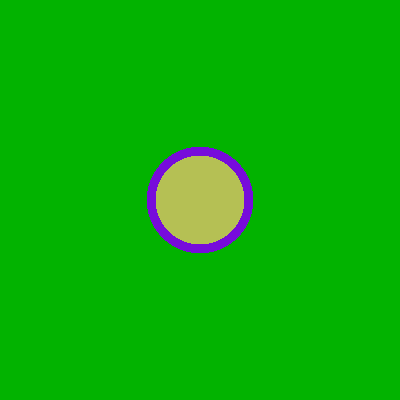

In [7]:
model.export_to_xml()
openmc.plot_inline(plots)

model.run() will return the resulting statepoint.h5 file that contains the results. 

In [8]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [11]:
# open the results file
with openmc.StatePoint(sp_filename) as sp:
    f4_tally = sp.get_tally(name='TBR')
    df = f4_tally.get_pandas_dataframe()

    # Code from J Shimwell Fusion Energy
    # sums up all the values in the mean column
    tally_mean_sum = df['mean'].sum()
    
    # sums up all the values in the std. dev. column
    tally_stdev_sum = df['std. dev.'].sum()

    print(f"TBR = {tally_mean_sum} +/- {tally_stdev_sum}")

    # gets the row that has li6 in the nuclide column and 
    lithium_6_contribution = df[df['nuclide'] == 'Li6']['mean'].sum()
    
    lithium_7_contribution = df[df['nuclide'] == 'Li7']['mean'].sum()
    
    print('The tritium breeding by lithium 6 is ', lithium_6_contribution)
    print('The tritium breeding by lithium 7 is ', lithium_7_contribution)

TBR = 0.031838733106509594 +/- 0.0004689666592114015
The tritium breeding by lithium 6 is  0.0004127493042636617
The tritium breeding by lithium 7 is  0.031425983802245934


/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


The above result is giving us the tritium breeding per source particle. However, if we want tritium production averaged over the entire volume, we'll need the cell's volume. 